# 독성 EDA: 원본에서 Morgan ECFP + 입체 변수 8개까지

**목적:** 기존 숫자 특징이 같지만 label이 다른 사례를 찾아, SMILES가 가지고 있던 입체 정보를 숫자로 복원한다. 원본과 모든 행을 보존하고 최종 숫자 입력의 label 충돌을 검사한다.

**읽는 순서:** 데이터와 label → 49개 상수 → 충돌 → 입체 정보 → 126개 탐색 → 8개 선정 → Morgan 재계산 → 최종 CSV 재검증 → 비용과 한계.

**증명 범위:** 현재 8,349행의 최종 숫자 입력이 동일한 그룹에 0과 1이 공존하지 않는다는 사실. 독성 기전, 미관측 물질의 안전성, 모델 정확도를 증명하지 않는다. SMILES·label·행 번호·그룹 번호를 충돌 검사 입력에 넣지 않는다.

실행 환경: 프로젝트의 `.venv_eda` Python, RDKit 2025.9.6, pandas/numpy/matplotlib/nbformat/nbclient. 기존 재현 스크립트 `run_stereo_eda.py`의 검증된 입체 파싱·환경 계산 함수를 재사용한다. 이 노트북을 미니프로젝트 또는 `04_노트북` 폴더에서 위에서 아래로 실행한다. 자료 위치는 [프로젝트 안내](../README.md)를 따른다.

In [1]:
from pathlib import Path
from collections import Counter, defaultdict
from itertools import combinations
from time import perf_counter
import csv, json, hashlib, platform, inspect, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from rdkit import Chem, DataStructs, rdBase
from rdkit.Chem import Draw, rdFingerprintGenerator
cwd = Path.cwd().resolve()
ROOT = next((p for p in [cwd, *cwd.parents, cwd/'미니프로젝트'] if (p/'02_데이터'/'train.csv').exists()), None)
assert ROOT is not None, '미니프로젝트 또는 04_노트북 폴더에서 실행하세요.'
sys.path.insert(0, str(ROOT/'03_분석'/'스크립트'))
import run_stereo_eda as history
font_manager.fontManager.addfont('/System/Library/Fonts/Supplemental/AppleGothic.ttf')
plt.rcParams.update({'font.family':'AppleGothic','axes.unicode_minus':False,'figure.dpi':130})
FIG = ROOT / '03_분석/시각화'; FIG.mkdir(exist_ok=True)
print({'Python':platform.python_version(),'RDKit':rdBase.rdkitVersion})
# 기존 함수의 실제 계산 코드를 이 실행 결과에도 공개한다.
print(inspect.getsource(history.environment))
print(inspect.getsource(history.describe))
history.self_check()

{'Python': '3.11.15', 'RDKit': '2025.09.6'}
def environment(mol, center):
    bonds = list(Chem.FindAtomEnvironmentOfRadiusN(mol, 2, center))
    atoms = {center}
    for bid in bonds:
        bond = mol.GetBondWithIdx(bid)
        atoms.update((bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()))
    return Chem.MolFragmentToSmiles(mol, atomsToUse=sorted(atoms), bondsToUse=bonds,
                                  rootedAtAtom=center, canonical=True, isomericSmiles=False)

def describe(smiles, with_morgan=True):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        raise ValueError(f'Cannot parse SMILES: {smiles}')
    potential = list(Chem.FindPotentialStereo(mol))
    rdCIPLabeler.AssignCIPLabels(mol)
    centers = {s.centeredOn for s in potential if s.type == Chem.StereoType.Atom_Tetrahedral}
    centers.update(a.GetIdx() for a in mol.GetAtoms() if a.HasProp('_CIPCode'))
    local, atom_info = Counter(), []
    for idx in sorted(centers):
        atom = mol.GetAtomWithIdx(idx)


## 1. 원본과 label 반전
SMILES는 분자를 글자로 적은 구조 설명서다. 3가지 fingerprint는 그 설명서를 숫자로 요약한 것이다. MolWt는 분자량, clogp는 기름/물 친화도의 계산 지표, sa_score는 합성 난이도 지표, qed는 약물 유사성 지표다. 네 값 모두 독성의 직접 측정값이 아니다.

원본 label에서 **0=독성, 1=비독성**이라는 프로젝트 합의를 따라 `1-label`을 한 번 적용한다. 이후 **1=독성, 0=비독성**이다. 원본 백업과 현재 파일의 모든 나머지 값이 같은지도 확인한다. 이는 연구 endpoint의 독성 정의를 새로 확인했다는 뜻은 아니다.

,원본 label,반전 label
label,,
0,3807,4542
1,4542,3807


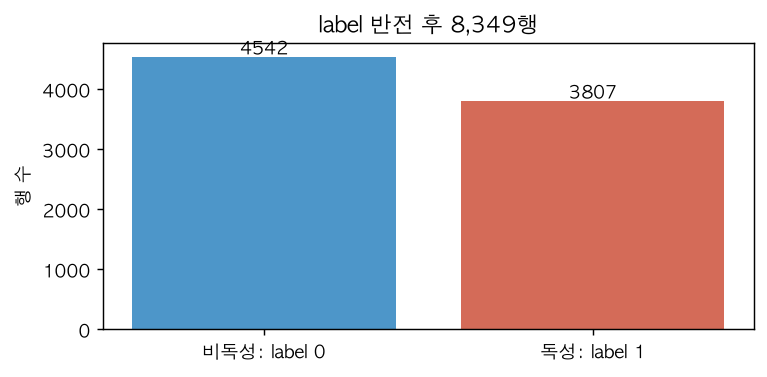

In [2]:
fpcols=[f'{kind}_{i}' for kind in ('ecfp','fcfp','ptfp') for i in range(1024)]
props=['MolWt','clogp','sa_score','qed']
dtypes={c:'int8' for c in fpcols+['label']}
dtypes.update({p:'float64' for p in props})
source_hash=hashlib.sha256((ROOT / '02_데이터/train.csv').read_bytes()).hexdigest()
original=pd.read_csv(ROOT / '01_원본자료/train_original_labels.csv.bak',dtype=dtypes)
current=pd.read_csv(ROOT / '02_데이터/train.csv',dtype=dtypes)
assert original.shape==current.shape==(8349,3078)
assert original.drop(columns='label').equals(current.drop(columns='label'))
assert set(original.label.unique())=={0,1}
df=original.copy(); df['label']=1-original.label
assert df.equals(current), '반전이 정확히 한 번 적용된 현재 파일과 일치해야 합니다.'
assert not df.isna().any().any()
display(pd.DataFrame({'원본 label':original.label.value_counts().sort_index(), '반전 label':df.label.value_counts().sort_index()}))
del current, original
fig,ax=plt.subplots(figsize=(6,3)); ax.bar(['비독성: label 0','독성: label 1'],[sum(df.label==0),sum(df.label==1)],color=['#4d96c9','#d46b58'])
for i,n in enumerate([sum(df.label==0),sum(df.label==1)]):ax.text(i,n+40,str(n),ha='center')
ax.set(ylabel='행 수',title='label 반전 후 8,349행'); fig.tight_layout(); fig.savefig(FIG/'01_label.png'); plt.show()

## 2. 왜 상수 49개를 제거하는가
모든 물질에서 똑같은 값은 물질 간 차이를 설명할 수 없다. 이번 데이터의 상수 49개는 모두 PTFP이고 모두 1이다. 숫자 특징에서만 제거하며 SMILES와 label은 유지한다. 이는 SMILES의 @를 지우는 처리와 다르다.

In [3]:
numeric=fpcols+props
constants=[c for c in numeric if df[c].nunique(dropna=False)==1]
assert len(constants)==49 and all(c.startswith('ptfp_') for c in constants)
assert all(df[c].iloc[0]==1 for c in constants)
basecols=[c for c in numeric if c not in constants]
display(pd.DataFrame({'제거 열':constants,'상수값':1}))
print('3078 - 49 =',len(basecols)+2,'열: SMILES와 label 포함')

,제거 열,상수값
0,ptfp_9,1
1,ptfp_37,1
2,ptfp_68,1
3,ptfp_100,1
4,ptfp_131,1
5,ptfp_141,1
6,ptfp_158,1
7,ptfp_161,1
8,ptfp_165,1
9,ptfp_173,1


3078 - 49 = 3029 열: SMILES와 label 포함


## 3. 충돌의 정의와 첫 진단
**충돌 1그룹:** 모델에게 들어가는 숫자가 완전히 같은데 label이 0과 1인 그룹. 구조 문자열이 다르다는 이유만으로 충돌이 없다고 처리하지 않는다. 기존 숫자 특징의 충돌과 PTFP만의 충돌을 구분한다.

같은 숫자를 받는 결정적 분류기는 그 그룹의 모든 행을 동시에 정답으로 맞힐 수 없다. 아래 최소 불가피 오류 수는 각 충돌 그룹에서 소수 label의 수를 합한 값이다.

In [4]:
def exact_keys(frame, columns):
    # 고정 길이 실제 값의 byte 표현을 사용한다. SMILES/label/ID를 넣지 않는다.
    bit=[c for c in columns if c in fpcols]
    real=[c for c in columns if c not in fpcols]
    b=frame[bit].to_numpy(dtype=np.uint8)
    r=frame[real].to_numpy(dtype=np.float64,copy=True); r[r==0]=0.0
    assert np.isfinite(r).all()
    return [b[i].tobytes()+r[i].tobytes() for i in range(len(frame))]
def audit(keys, labels):
    groups=defaultdict(list)
    for i,k in enumerate(keys): groups[k].append(i)
    mixed=[idx for idx in groups.values() if len(set(int(labels[i]) for i in idx))>1]
    return {'충돌 그룹':len(mixed),'충돌 행':sum(map(len,mixed)),
            '최소 불가피 오류':sum(min(Counter(int(labels[i]) for i in idx).values()) for idx in mixed)}, mixed
labels=df.label.to_numpy()
basekeys=exact_keys(df,basecols)
baseline, mixed=audit(basekeys,labels)
pt_result,_=audit(exact_keys(df,[c for c in fpcols if c.startswith('ptfp_')]),labels)
assert baseline=={'충돌 그룹':33,'충돌 행':73,'최소 불가피 오류':34}
assert pt_result['충돌 그룹']==57
print('PTFP만:',pt_result,' / 기존 전체:',baseline)
meta=pd.read_csv(ROOT / '03_분석/진단표/충돌33그룹_입체분석.csv')
assert len(meta)==73 and meta.conflict_group.nunique()==33
assert set(meta.csv_row.astype(int)-2)==set(i for g in mixed for i in g)
# 연결 구조는 같고, 반대 label의 입체 포함 구조는 다르다는 사실을 검증한다.
for gid,g in meta.groupby('conflict_group'):
    assert g.canonical_connectivity.nunique()==1
    for _,a in g.iterrows():
        for _,b in g.iterrows():
            if a.label!=b.label: assert a.canonical_isomeric!=b.canonical_isomeric
print('33그룹 모두 같은 연결 구조 안에서 입체 포함 표현에 차이가 있습니다.')
display(meta[['conflict_group','csv_row','label','SMILES']].head(10))

PTFP만: {'충돌 그룹': 57, '충돌 행': 123, '최소 불가피 오류': 58}  / 기존 전체: {'충돌 그룹': 33, '충돌 행': 73, '최소 불가피 오류': 34}
33그룹 모두 같은 연결 구조 안에서 입체 포함 표현에 차이가 있습니다.


,conflict_group,csv_row,label,SMILES
0,C01,100,1,CN1CC=CCC(C1)c2ccc(Cl)c(Cl)c2
1,C01,101,0,CN1CC=CC[C@@H](C1)c2ccc(Cl)c(Cl)c2
2,C02,379,0,CC(N1C=C(Cl)C=C(C(=O)N)C1=N)c2cccc(c2)C#N
3,C02,380,0,C[C@@H](N1C=C(Cl)C=C(C(=O)N)C1=N)c2cccc(c2)C#N
4,C02,381,1,C[C@H](N1C=C(Cl)C=C(C(=O)N)C1=N)c2cccc(c2)C#N
5,C03,877,0,O=C1NN=C([C@H]2C[C@@H]12)c3ccc(OC4CCN(CC4)C5CC...
6,C03,878,1,O=C1NN=C([C@@H]2C[C@H]12)c3ccc(OC4CCN(CC4)C5CC...
7,C04,968,0,CN(C)[C@@H]1CC[C@@H](CC1)c2ccc(OCCCN3CCCCC3)cc2
8,C04,969,1,CN(C)[C@@H]1CC[C@H](CC1)c2ccc(OCCCN3CCCCC3)cc2
9,C05,1710,0,C[C@@H]1CCCN1CCCOc2ccc(cc2)N3C(=Nc4ccccc4C3=O)C


## 4. R/S, r/s, unassigned를 초등학생에게 설명하면
왼손과 오른손은 손가락 수가 같지만 겹쳐지지 않는다. 분자도 연결 부품이 같아도 공간 방향이 다를 수 있다. **R/S는 정해진 CIP 우선순위 규칙으로 붙이는 공간 배치 이름**이고, 독성/안전 표시가 아니다. **r/s는 특별한 대칭 관계에서 쓰는 유사비대칭 배치 이름**이라 대문자와 따로 센다.

`unassigned`는 입체 중심 후보인데 입력에 방향이 지정되지 않아 CIP 이름을 붙이지 못한 수다. 이것만으로 라세미 혼합물이라고 단정하지 않는다. @와 @@는 SMILES에 적힌 이웃 순서 기준이므로 문자 개수를 세거나 @=R로 바꾸지 않는다. RDKit으로 분자를 읽고 실제 CIP를 계산한다.

## 5. 126개 탐색에서 8개로 줄인 근거
126개는 후보 탐색용 기록이다. 먼저 R−S, r−s, 미지정 수 3개를 유지한다. 그래도 같은 숫자인 반대 label 쌍을 구분할 국소 환경 변수만 찾는다. 국소 환경 97개는 기존 충돌 사례에서 발견한 후보라 독립 검증 데이터가 아니다.

아래는 기존 126개 탐색 CSV를 읽어 3개 요약 뒤 남은 쌍과, 다섯 국소 변수의 조건부 최소성을 다시 계산한다. **3개 요약 고정 + 이 후보군 + 관측된 충돌**이라는 조건에서 최소 5개다. 어떤 데이터에도 8개가 최적이라는 주장이 아니다.

In [5]:
dictionary=pd.read_csv(ROOT / '03_분석/진단표/입체_파생변수_사전.csv')
localdict={r.feature:(r.environment_radius2,r.CIP_state) for r in dictionary.itertuples() if r.kind=='local_stereo_count'}
assert len(localdict)==97
BASE=['stereo_R_minus_S','stereo_r_minus_s','stereo_unassigned_count']
conflict_rows=set(meta.csv_row.astype(int))
candidate={}
with (ROOT / '02_데이터/중간결과/train_eda_exploratory126.csv').open() as f:
    for rownum,row in enumerate(csv.DictReader(f),2):
        if rownum in conflict_rows: candidate[rownum]={k:float(v) for k,v in row.items() if k.startswith('stereo_')}
unresolved=[]
for gid,g in meta.groupby('conflict_group',sort=False):
    for a,b in combinations(g.to_dict('records'),2):
        if a['label']!=b['label'] and all(candidate[a['csv_row']][k]==candidate[b['csv_row']][k] for k in BASE):
            unresolved.append((gid,int(a['csv_row']),int(b['csv_row'])))
assert len(unresolved)==8 and len({x[0] for x in unresolved})==5
masks={}
for name in localdict:
    mask=sum(1<<i for i,(_,a,b) in enumerate(unresolved) if candidate[a][name]!=candidate[b][name])
    if mask: masks.setdefault(mask,name)
goal=(1<<len(unresolved))-1
selected=None
for size in range(1,len(masks)+1):
    for choice in combinations(masks.items(),size):
        union=0
        for bits,_ in choice: union|=bits
        if union==goal: selected=[name for _,name in choice]; break
    if selected is not None: break
assert selected==['stereo_env_001','stereo_env_006','stereo_env_046','stereo_env_054','stereo_env_084']
selected_keys=[localdict[n] for n in selected]
features=BASE+selected
coverage=[]
for name in selected:
    gids=sorted({gid for gid,a,b in unresolved if candidate[a][name]!=candidate[b][name]})
    coverage.append({'변수':name,'반경2 연결 환경':localdict[name][0],'세는 방향':localdict[name][1],'남은 충돌 그룹':', '.join(gids)})
coverage=pd.DataFrame(coverage)
display(coverage)
print('전역3개 이후:',sorted({x[0] for x in unresolved}),'/ 반대 label 쌍:',len(unresolved))

,변수,반경2 연결 환경,세는 방향,남은 충돌 그룹
0,stereo_env_001,C(C(C)(C)O)(OC)C(c)O,R,C25
1,stereo_env_006,C(C(N)=O)(CN)C(c)C,R,C19
2,stereo_env_046,C(N)(CO)C(O)C,R,C27
3,stereo_env_054,C(O)(C(c)O)C(C)O,R,C21
4,stereo_env_084,C1(CC1C)C(=O)N,R,C03


전역3개 이후: ['C03', 'C19', 'C21', 'C25', 'C27'] / 반대 label 쌍: 8


## 6. 왜 이렇게 계산하는가
- `R−S`: 전체 R과 S 개수를 별도 2열 대신 차이 1열로 요약한다. 같은 개수가 뒤집히면 부호가 바뀐다. 분자별 모든 배치를 유일하게 표현하지는 않는다.
- `r−s`: 소문자 정보를 대문자에 섞지 않고 같은 방식으로 요약한다.
- `unassigned_count`: 방향이 알려진 구조와 방향이 지정되지 않은 구조를 같은 정보 수준으로 처리하지 않게 한다.
- `stereo_env_*`: 해당 **연결 환경에서 중심이 R인 원자의 개수**다. 중심에서 결합 두 번까지의 부분 연결 구조를 정규화하여 비교한다. 연결 모양과 중심 방향을 따로 읽기 위해 환경 문자열에는 입체 표기를 포함하지 않고 CIP를 함께 사용한다. 반경2는 기존 탐색과 Morgan 반경을 맞추는 재현 가능한 국소 범위이며 생물학적으로 최적임을 증명한 값은 아니다.

예를 들어 빨간 위치 R·파란 위치 S와 빨간 위치 S·파란 위치 R은 모두 R−S=0이다. 빨간 위치의 R 개수를 추가하면 1과 0으로 구분된다. 단순 합계가 놓치는 **어디의 방향이 다른가**를 다섯 열이 보완한다. 번호 001·006·046·054·084는 환경 사전 번호이며 독성 순위가 아니다. R만 세는 것은 이번 잔여 쌍을 구분하는 데 충분했기 때문이다. 미지정 수와 전역 요약도 함께 사용하며, R=독성이라는 규칙을 넣지 않는다.

In [6]:
started=perf_counter()
records=[history.describe(s,with_morgan=False) for s in df.SMILES]
small=np.array([[d['scalar'][n] for n in BASE]+[d['local'][k] for k in selected_keys] for d in records],dtype=np.int64)
for j,name in enumerate(features): df[name]=small[:,j]
# 원자 순서를 바꾼 같은 SMILES에서도 같은 값을 내는지 충돌 73행 모두 점검한다.
for rownum in sorted(conflict_rows):
    d=records[rownum-2]
    alternate=Chem.MolToSmiles(d['mol'],doRandom=True,isomericSmiles=True)
    alt=history.describe(alternate,with_morgan=False)
    assert [alt['scalar'][n] for n in BASE]+[alt['local'][k] for k in selected_keys]==small[rownum-2].tolist()
print('8개 변수 추출 및 검증:',round(perf_counter()-started,3),'초')
summary3,_=audit(exact_keys(df,basecols+BASE),labels)
compact8,_=audit(exact_keys(df,basecols+features),labels)
assert summary3['충돌 그룹']==5 and compact8['충돌 그룹']==0
print('전역3개:',summary3,'/ 8개:',compact8)
# 8개 변수의 실제 표와 선정 그룹을 눈으로 확인한다.
display(df.loc[meta.csv_row.astype(int)-2,['SMILES','label']+features].head(12))

8개 변수 추출 및 검증: 7.423 초
전역3개: {'충돌 그룹': 5, '충돌 행': 12, '최소 불가피 오류': 6} / 8개: {'충돌 그룹': 0, '충돌 행': 0, '최소 불가피 오류': 0}


,SMILES,label,stereo_R_minus_S,stereo_r_minus_s,stereo_unassigned_count,stereo_env_001,stereo_env_006,stereo_env_046,stereo_env_054,stereo_env_084
98,CN1CC=CCC(C1)c2ccc(Cl)c(Cl)c2,1,0,0,1,0,0,0,0,0
99,CN1CC=CC[C@@H](C1)c2ccc(Cl)c(Cl)c2,0,1,0,0,0,0,0,0,0
377,CC(N1C=C(Cl)C=C(C(=O)N)C1=N)c2cccc(c2)C#N,0,0,0,1,0,0,0,0,0
378,C[C@@H](N1C=C(Cl)C=C(C(=O)N)C1=N)c2cccc(c2)C#N,0,1,0,0,0,0,0,0,0
379,C[C@H](N1C=C(Cl)C=C(C(=O)N)C1=N)c2cccc(c2)C#N,1,-1,0,0,0,0,0,0,0
875,O=C1NN=C([C@H]2C[C@@H]12)c3ccc(OC4CCN(CC4)C5CC...,0,0,0,0,0,0,0,0,1
876,O=C1NN=C([C@@H]2C[C@H]12)c3ccc(OC4CCN(CC4)C5CC...,1,0,0,0,0,0,0,0,0
966,CN(C)[C@@H]1CC[C@@H](CC1)c2ccc(OCCCN3CCCCC3)cc2,0,0,-2,0,0,0,0,0,0
967,CN(C)[C@@H]1CC[C@H](CC1)c2ccc(OCCCN3CCCCC3)cc2,1,0,2,0,0,0,0,0,0
1708,C[C@@H]1CCCN1CCCOc2ccc(cc2)N3C(=Nc4ccccc4C3=O)C,0,1,0,0,0,0,0,0,0


## 7. 최종 Morgan ECFP 재계산
ECFP는 각 원자 주변의 연결 정보를 단계적으로 확장해 고정 길이 숫자로 담는 방식이고 Morgan 알고리즘으로 계산한다. 여기서는 **반경2, 1,024비트, includeChirality=True**를 명시한다. 통상 ECFP4에 해당하는 반경이다. 기존 제공 ECFP의 생성 설정은 알려져 있지 않으므로, 이 단계는 동일 계산의 반복이 아니라 명시적인 재생성이다.

새 Morgan 1,024열로 기존 ecfp 열만 대체한다. FCFP와 상수 제거 후 PTFP, 물성 4개는 유지하고 입체 변수 8개를 붙인다. 기존 실험 파일 `train_eda_cip_fp.csv`의 사용자 정의 CIP 원자 불변량 방식과 구별된다. 여기서는 표준 Morgan의 chirality 옵션을 사용한다.

In [7]:
generator=rdFingerprintGenerator.GetMorganGenerator(radius=2,fpSize=1024,includeChirality=True)
new_ecfp=np.empty((len(df),1024),dtype=np.int8)
for i,d in enumerate(records): DataStructs.ConvertToNumpyArray(generator.GetFingerprint(d['mol']),new_ecfp[i])
final=df.copy()
final[[f'ecfp_{i}' for i in range(1024)]]=new_ecfp
morgan_only,_=audit(exact_keys(final,basecols),labels)
finalcols=basecols+features
final_result,final_mixed=audit(exact_keys(final,finalcols),labels)
assert final_result=={'충돌 그룹':0,'충돌 행':0,'최소 불가피 오류':0}
assert len(finalcols)==3035
print('Morgan만:',morgan_only,'/ Morgan+8개:',final_result)
output=final[['SMILES']+finalcols+['label']]
assert output.shape==(8349,3037)
assert output.SMILES.equals(df.SMILES) and output.label.equals(df.label)
assert output[[c for c in basecols if not c.startswith('ecfp_')]].equals(df[[c for c in basecols if not c.startswith('ecfp_')]])
OUTPUT=ROOT / '02_데이터/train_final_morgan_8vars.csv'
output.to_csv(OUTPUT,index=False)
print('최종 파일:',OUTPUT.name,'/ 크기:',OUTPUT.stat().st_size,'bytes')

Morgan만: {'충돌 그룹': 6, '충돌 행': 12, '최소 불가피 오류': 6} / Morgan+8개: {'충돌 그룹': 0, '충돌 행': 0, '최소 불가피 오류': 0}


최종 파일: train_final_morgan_8vars.csv / 크기: 51462560 bytes


## 8. 저장된 CSV를 다시 읽어서 독립 검증
메모리 안에서 0이라는 것만 확인하지 않고 실제 전달 파일을 재검사한다. 같은 숫자 행들을 정렬한 뒤 인접 행의 label이 다른지 검사한다. 행 삭제·label 수정·SMILES/ID를 넣어 충돌을 숨기는 방식은 사용하지 않았다.

PASS: 8,349행 유지, label 유지, SMILES 유지, 원본 유지, 최종 숫자 입력 충돌 0건


,단계,충돌 그룹,충돌 행,최소 불가피 오류
0,기존 전체,33,73,34
1,전역 3개 추가,5,12,6
2,기존 + 8개,0,0,0
3,Morgan만 재생성,6,12,6
4,Morgan + 8개 최종,0,0,0


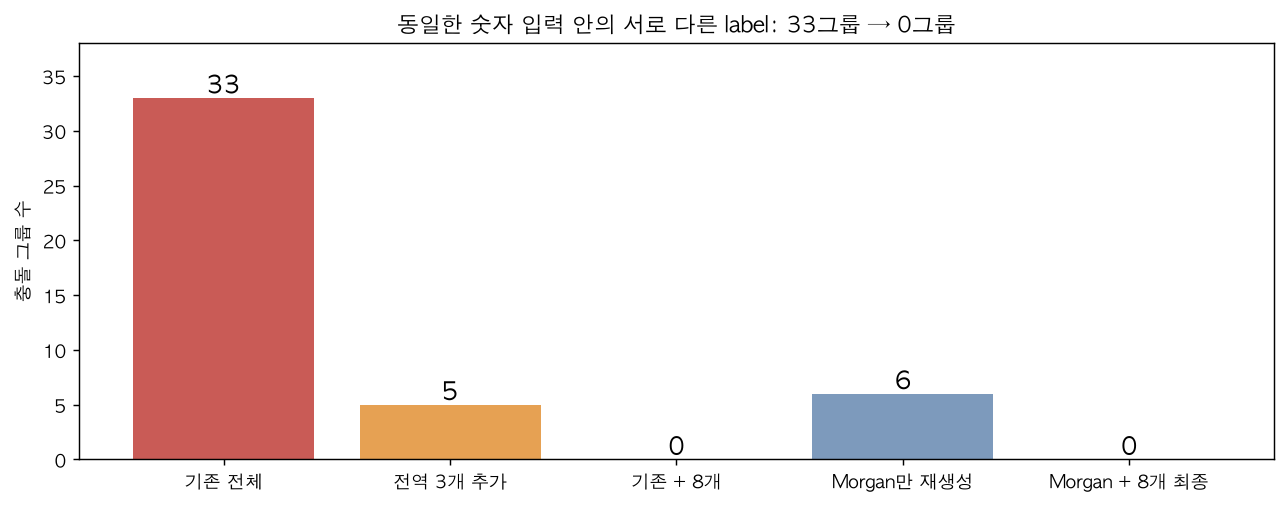

In [8]:
check=pd.read_csv(OUTPUT,dtype={**dtypes,**{c:'int64' for c in features}})
assert check.shape==(8349,3037)
assert check.SMILES.equals(df.SMILES) and check.label.equals(df.label)
# 위의 byte-key 그룹 함수와 다른 방식: 전체 숫자 벡터를 정렬해서 인접 label 검사.
order=check.sort_values(finalcols+['label'],kind='stable').index.to_numpy()
matrix=check[finalcols].to_numpy(dtype=np.float64)[order]
y=check.label.to_numpy()[order]
same=np.all(matrix[:-1]==matrix[1:],axis=1)
assert not np.any(same & (y[:-1]!=y[1:])), '저장 파일에 반대 label의 동일 숫자 입력이 있습니다.'
assert hashlib.sha256((ROOT / '02_데이터/train.csv').read_bytes()).hexdigest()==source_hash
print('PASS: 8,349행 유지, label 유지, SMILES 유지, 원본 유지, 최종 숫자 입력 충돌 0건')
del matrix, check
results=pd.DataFrame([{'단계':name,**result} for name,result in [('기존 전체',baseline),('전역 3개 추가',summary3),('기존 + 8개',compact8),('Morgan만 재생성',morgan_only),('Morgan + 8개 최종',final_result)]])
display(results)
fig,ax=plt.subplots(figsize=(10,4))
colors=['#c95b56','#e6a153','#6caa78','#7d9abc','#25865e']
ax.bar(results['단계'],results['충돌 그룹'],color=colors)
for i,v in enumerate(results['충돌 그룹']): ax.text(i,v+0.4,str(v),ha='center',fontsize=14)
ax.set(title='동일한 숫자 입력 안의 서로 다른 label: 33그룹 → 0그룹',ylabel='충돌 그룹 수',ylim=(0,38))
fig.tight_layout(); fig.savefig(FIG/'02_충돌감소.png'); plt.show()

## 9. 33개 그룹이 모두 검증되었는지 확인
각 열의 빨간 칸은 그 단계에서 해당 원래 그룹 안에 서로 다른 label의 동일 입력이 여전히 존재한다는 뜻이다. 마지막 열은 33개 그룹 모두 0이다. 이 표와 별개로 바로 위에서 전체 8,349행에 대해 새로운 충돌까지 검사했다.

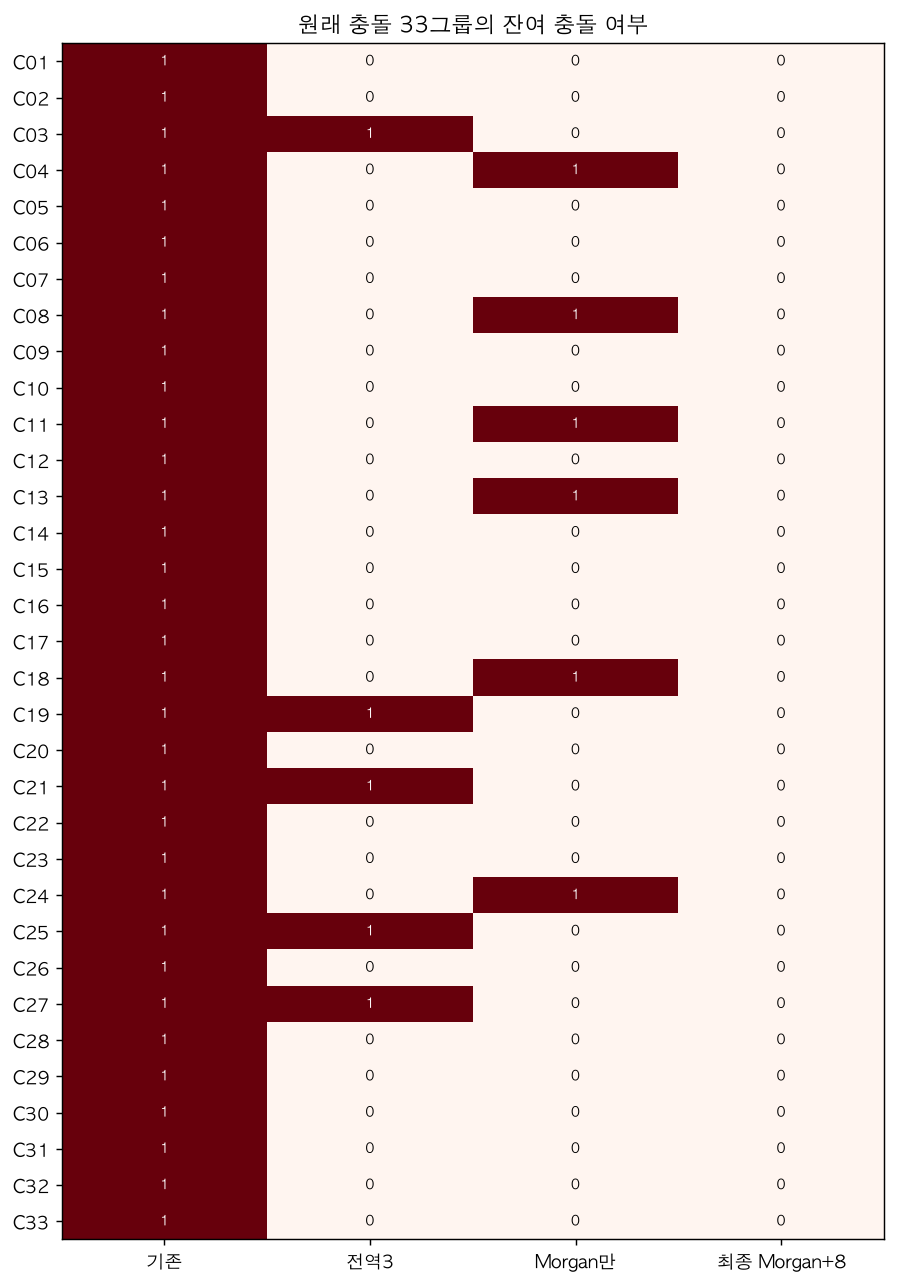

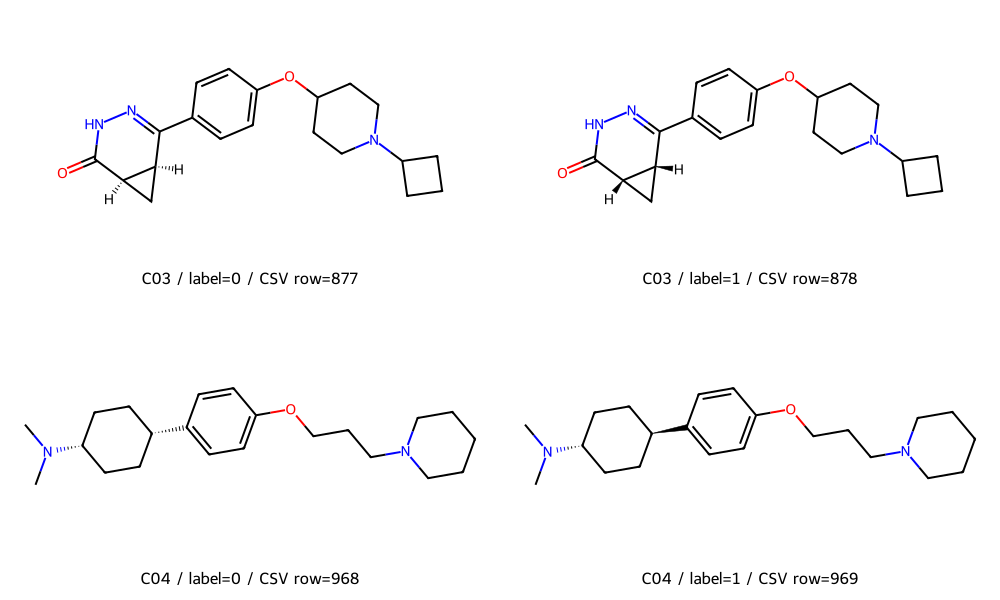

In [9]:
stage_keys=[basekeys,exact_keys(df,basecols+BASE),exact_keys(final,basecols),exact_keys(final,finalcols)]
gids=sorted(meta.conflict_group.unique())
heat=[]
for gid in gids:
    idx=(meta.loc[meta.conflict_group==gid,'csv_row'].astype(int)-2).tolist()
    heat.append([int(any(keys[a]==keys[b] and labels[a]!=labels[b] for a,b in combinations(idx,2))) for keys in stage_keys])
fig,ax=plt.subplots(figsize=(7,10))
ax.imshow(heat,cmap='Reds',vmin=0,vmax=1,aspect='auto')
ax.set(xticks=range(4),xticklabels=['기존','전역3','Morgan만','최종 Morgan+8'],yticks=range(len(gids)),yticklabels=gids,title='원래 충돌 33그룹의 잔여 충돌 여부')
for i,row in enumerate(heat):
    for j,v in enumerate(row):ax.text(j,i,str(v),ha='center',va='center',fontsize=8,color='white' if v else 'black')
fig.tight_layout(); fig.savefig(FIG/'03_33그룹_검증.png'); plt.show()
assert np.array(heat)[:,-1].sum()==0
# 실제 구조 예: 국소 환경 필요 그룹 C03, 소문자 CIP 사례 C04.
examples=meta[meta.conflict_group.isin(['C03','C04'])]
mols=[Chem.MolFromSmiles(s) for s in examples.SMILES]
legends=[f'{r.conflict_group} / label={r.label} / CSV row={r.csv_row}' for r in examples.itertuples()]
img=Draw.MolsToGridImage(mols,molsPerRow=2,subImgSize=(500,300),legends=legends)
if hasattr(img,'save'): img.save(str(FIG/'04_구조예시.png'))
else: (FIG/'04_구조예시.png').write_bytes(img.data)
display(img)

## 10. AX 운영 비용과 탐색 한계
기존 측정은 동일 로컬 환경에서 8,349분자의 특징 추출을 3회 실행한 중앙값이며 CSV 입출력·모델 학습·서버 비용을 포함하지 않는다. 126→8은 **추가 변수**의 93.65% 감소다. 전체 입력 크기가 그 비율로 줄어들었다는 뜻이 아니다. 지금 최종 Morgan 재생성까지의 서비스 비용과도 다르다.

PTFP와 ECFP/FCFP/물성을 64가지 조합으로 비교한 기록도 함께 보존한다. 이미 같은 기존 값끼리 곱하거나 더하면 같은 결과다. 따라서 충돌을 구분하려면 SMILES에 있던 새 구조 정보를 읽어야 한다. MolWt/clogp/SA/QED 조합은 다른 그룹이나 조건별 패턴을 살피는 역할을 한다.

서로 같은 국소 R 환경도 전체 분자가 달라지면 독성 방향이 바뀌는 사례가 있었다. 특정 환경의 R을 보편적 독성 원인으로 해석하지 않는다. 관측 충돌을 보며 고른 8개라, 미래 예측은 분자 계열 단위 분리와 독립 평가가 필요하다. SMILES에 없는 실험 조건, 용량, 대사 등은 이 전처리만으로 복원할 수 없다.

,과거 측정 방식,8349분자 중앙값(초),분자당(ms)
0,탐색126열,7.084746,0.848574
1,축소8열,4.187874,0.501602
2,기존1024열대체,4.659546,0.558096


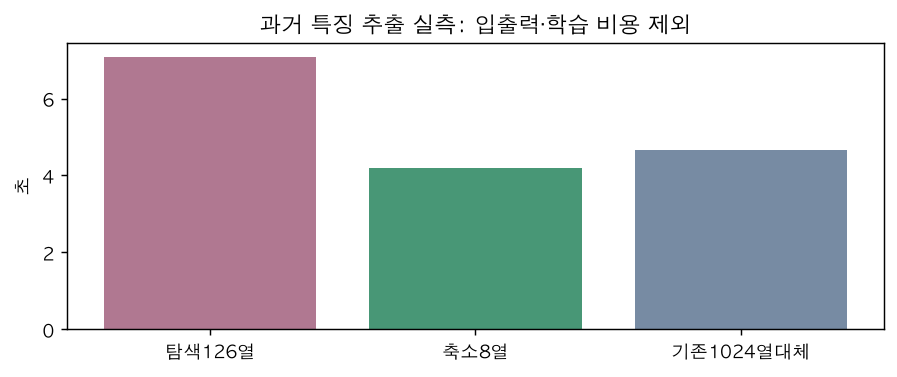

,features,conflict_groups,conflict_rows,minimum_errors_from_identical_inputs
0,PTFP,57,123,58
1,PTFP + ecfp,34,75,35
2,PTFP + fcfp,38,83,39
3,PTFP + ecfp + fcfp,34,75,35
4,PTFP + MolWt,52,112,53
5,PTFP + ecfp + MolWt,34,75,35
6,PTFP + fcfp + MolWt,38,83,39
7,PTFP + ecfp + fcfp + MolWt,34,75,35
8,PTFP + clogp,50,108,51
9,PTFP + ecfp + clogp,34,75,35


,자료,bytes
0,PTFP_64조합_충돌진단.csv,2552
1,compact_eda_audit.json,3595
2,eda_analysis.json,3634
3,make_compact_eda.py,9840
4,run_stereo_eda.py,27830
5,train.csv,52154470
6,train_eda.csv,51470906
7,train_eda_cip_fp.csv,51341975
8,train_eda_exploratory126.csv,53858150
9,train_final_morgan_8vars.csv,51462560


최종 검증 보고서 저장 완료


In [10]:
old=json.loads((ROOT / '03_분석/검증기록/compact_eda_audit.json').read_text())
cost=pd.DataFrame([{'과거 측정 방식':k,'8349분자 중앙값(초)':v['median_seconds_8349'],'분자당(ms)':v['median_ms_per_molecule']} for k,v in old['benchmark'].items()])
display(cost)
fig,ax=plt.subplots(figsize=(7,3))
ax.bar(cost['과거 측정 방식'],cost['8349분자 중앙값(초)'],color=['#b07891','#489776','#778ba3'])
ax.set(title='과거 특징 추출 실측: 입출력·학습 비용 제외',ylabel='초');fig.tight_layout();fig.savefig(FIG/'05_AX비용.png');plt.show()
display(pd.read_csv(ROOT / '03_분석/진단표/PTFP_64조합_충돌진단.csv').head(12))
manifest=[]
for p in sorted(ROOT.rglob('*')):
    if p.is_file() and (p.suffix in {'.md','.csv','.json','.pdf','.py'} or p.name.endswith('.bak')):
        manifest.append({'자료':str(p.relative_to(ROOT)),'bytes':p.stat().st_size})
display(pd.DataFrame(manifest))
audit_report={'rows':8349,'columns':3037,'removed_columns':constants,'features':features,
 'selected_local_coverage':coverage.to_dict('records'),'morgan':{'radius':2,'bits':1024,'includeChirality':True},
 'stages':results.to_dict('records'),'source_sha256':source_hash,'output_sha256':hashlib.sha256(OUTPUT.read_bytes()).hexdigest(),
 'rdkit':rdBase.rdkitVersion,'scope':'현재 데이터의 동일 숫자 입력-label 충돌 없음. 인과 설명/독립 예측 성능 증명 아님.'}
(ROOT / '03_분석/검증기록/최종_Morgan8_검증.json').write_text(json.dumps(audit_report,ensure_ascii=False,indent=2))
print('최종 검증 보고서 저장 완료')

## 발표 및 참고 자료
- `발표_10~15분_전체스크립트.md`: 그대로 읽는 대본과 8개 계산·선정 근거, 비용, 질의응답.
- `계산독성학_30분_가이드.md`: 도메인 배경과 문헌 11편.
- `충돌_EDA_분석.md`: 126개 탐색의 경위와 관측 패턴.
- `발표용_전처리결정과AX비용.md`: 8개 축소 및 사용자 정의 CIP-Morgan 실험의 비용·한계.
- `충돌33그룹_구조비교.pdf`: 33그룹 전체 구조 그림.
- 기존 MD/CSV/JSON/PDF/스크립트와 원본은 삭제하거나 덮어쓰지 않았다.

문헌 연결: [Born 2023 입체 SMILES와 독성](https://doi.org/10.1039/D2DD00099G), [Baimacheva 2025 입체 표현 비교](https://doi.org/10.1186/s13321-025-01080-7), [MolToxPred 특징 결합](https://doi.org/10.1039/D3RA07322J). 각 연구의 데이터와 endpoint는 이번 프로젝트와 동일하다고 가정하지 않는다.

**발표의 마지막 문장:** “입체 정보를 보존한 전처리로 현재 데이터의 표현 충돌을 0건으로 줄였습니다. 다음 단계는 계열 단위 독립 평가와 잔여 독성 기전 검토입니다.”